# General statistics

Computes missing general stats, then plots them in raw units: per method (dots = samples) and per cell type (dots = methods).

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parents[0]))
from cellseg_benchmark._constants import BASE_PATH, celltype_groups, main_methods, method_names, methods_3D
from cellseg_benchmark.metrics import clean_method_name, compute_metric_for_all_methods, extract_general_stats

cohorts = ["aging", "ABCAtlas", "VizgenMouseBrain"]
tables_dir = Path(BASE_PATH) / "metrics" / "merged" / "benchmark_tables"
out_dir = Path(BASE_PATH) / "metrics" / "merged" / "general_stats"
out_dir.mkdir(exist_ok=True)
group_of = {"all": "All cells"} | {t: g for g, types in celltype_groups.items() for t in types}
stats = {"volume_final": "Volume (µm³)", "elongation": "Elongation", "intensities_DAPI": "DAPI", "n_counts": "Transcripts per cell", "n_genes": "Genes per cell"}

font_manager.fontManager.addfont(Path(BASE_PATH) / "misc" / "Arial.ttf")
plt.rcParams.update({"font.family": "Arial", "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.size": 2.5, "xtick.major.width": 0.6, "ytick.major.size": 0, "svg.fonttype": "none", "pdf.fonttype": 42})
cohort_names = {"aging": "Aging", "ABCAtlas": "ABC Atlas", "VizgenMouseBrain": "Vizgen"}
cohort_colors = {"Aging": "#3B6FB6", "ABC Atlas": "#D17A22", "Vizgen": "#9A4FB3"}
dim_colors = {"2D": "#a3a3a3", "3D": "#3d3d3d"}
median = dict(estimator="median", errorbar=None, linestyle="none", marker="|", markersize=8, markeredgewidth=1.2, legend=False)
legend = dict(frameon=False, title="", handletextpad=0.3, borderaxespad=0)


def style(ax, col, n, zebra=True):
    """Shared panel style: log scale for skewed metrics, two-line title, zebra rows as in the benchmark table."""
    if col in {"Volume (µm³)", "Transcripts per cell", "Cells/mm²", "Cell fraction"}:
        ax.set_xscale("log")
        span = ax.get_xlim()[1] / ax.get_xlim()[0]
        if span < 30:
            ax.xaxis.set_major_locator(plt.LogLocator(subs=(1, 3)))
        elif span > 300:
            ax.xaxis.set_major_locator(plt.LogLocator(base=100))
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(col.replace(" (", "\n(").replace(" per ", "\nper ").replace(" intensity", "\nintensity").replace(" fraction", "\nfraction"), linespacing=0.95)
    ax.set(xlabel="", ylabel="")
    for i in range(0, n if zebra else 0, 2):
        ax.axhspan(i - 0.5, i + 0.5, color="0.94", lw=0, zorder=0)
    ax.set_ylim(n - 0.5, -0.5)
    sns.despine(ax=ax, left=True)

/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
for cohort in cohorts:
    compute_metric_for_all_methods(extract_general_stats, cohort=cohort, results_name="general_stats/general_stats.csv")

gs, density = (pd.concat([pd.read_csv(Path(BASE_PATH) / "metrics" / c / name / f"{name}.csv", index_col=0).assign(cohort=c) for c in cohorts])
               for name in ["general_stats", "cell_density"])
gs = gs.merge(density[["sample", "method", "tissue_mm2"]], on=["sample", "method"], how="left")
gs = gs.query("sample not in ['all', 'all_samples']").assign(method=lambda d: d.method.map(clean_method_name), group=lambda d: d.cell_type_revised.map(group_of))
gs = gs[gs.method.isin(main_methods) & gs.group.notna()].rename(columns=stats).assign(**{"Cells/mm²": lambda d: d.n_cells / d.tissue_mm2})

1/45 extract_general_stats already computed for Proseg_3D_Cellpose_1_nuclei_model. Set overwrite=True to recompute
2/45 extract_general_stats already computed for Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8. Set overwrite=True to recompute
3/45 extract_general_stats already computed for CellSAM_DAPI. Set overwrite=True to recompute
4/45 extract_general_stats already computed for vpt_2D_DAPI_nuclei. Set overwrite=True to recompute
5/45 extract_general_stats already computed for Cellpose_1_nuclei_model. Set overwrite=True to recompute
6/45 extract_general_stats already computed for Baysor_2D_Cellpose_2_DAPI_PolyT_0.2. Set overwrite=True to recompute
7/45 extract_general_stats already computed for Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8. Set overwrite=True to recompute
8/45 extract_general_stats already computed for Negative_Control_Rastered_5. Set overwrite=True to recompute
9/45 extract_general_stats already computed for Cellpose_2_DAPI_PolyT. Set overwrite=True to recompute
10/45 extra

## Methods

Ordered by overall score, as in the benchmark table (`all/combined.csv` from metrics_summary_table). Dots = samples (coloured by cohort), bar = median. Plotted next to QC below, rows shared.


In [3]:
alls = gs[gs.group == "All cells"]
methods = [m for m in pd.read_csv(tables_dir / "all" / "combined.csv").method if m in set(alls.method)]
alls.to_csv(out_dir / "method_general.csv", index=False)

## Quality control

Cells kept and removed per QC step (from merge_adata logs; numbers = cells before QC, all sections) and assigned transcripts lost with them; bars = cohort mean, dots = cohorts. Transcript density: cells in the lowest or highest 1% of transcripts per µm³, removed during normalization. Right: share of all transcripts assigned to cells, split into kept and removed by QC (bar end = before QC) (mean over samples, then cohorts).

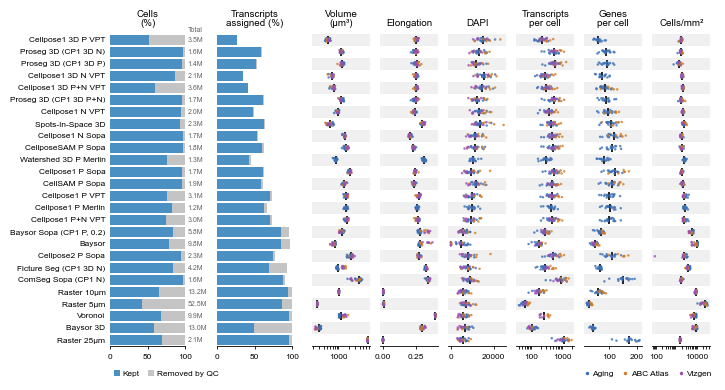

In [4]:
patterns = {
    "start": r"before filtering spatial outliers: (\d+)",
    "Outside tissue": r"after filtering spatial outliers:\s+(\d+)",
    "Low counts or volume": r"after filtering low-quality or volume outliers:\s+(\d+)",
    "Transcript density (top/bottom 1%)": r"during normalization: \d+ -> (\d+)",
}
rows = []
for cohort in cohorts:
    for log in (Path(BASE_PATH) / "misc" / "logs" / "merged").glob(f"merge_adata_{cohort}_*.log"):
        text = log.read_text()
        n = {k: int(m[-1]) if (m := re.findall(p, text)) else None for k, p in patterns.items()}
        raw = log.stem.removeprefix(f"merge_adata_{cohort}_")
        if None not in n.values() and raw in method_names:
            rows.append({"cohort": cohort, "method": clean_method_name(raw)} | n)
qc = pd.DataFrame(rows)
steps = list(patterns)[1:]
left = qc[["start", *steps]].to_numpy()
qc[steps] = 100 * (left[:, :-1] - left[:, 1:]) / qc[["start"]].to_numpy()

tx = pd.concat([pd.read_csv(Path(BASE_PATH) / "metrics" / c / "assigned_transcripts/assigned_transcript_counts.csv", index_col=0).assign(cohort=c) for c in cohorts])
tx = (tx.query("sample not in ['all', 'all_samples']").groupby(["cohort", "sample", "method"])[["assigned_count_raw", "assigned_count_qced", "total_count"]].sum()
      .pipe(lambda d: pd.DataFrame({"Transcripts removed (%)": 100 * (1 - d.assigned_count_qced / d.assigned_count_raw),
                                    "Before QC": 100 * d.assigned_count_raw / d.total_count, "After QC": 100 * d.assigned_count_qced / d.total_count}))
      .groupby(["cohort", "method"]).mean().reset_index())
tx["method"] = tx.method.map(clean_method_name)
qc = qc.merge(tx, on=["cohort", "method"], how="left")
qc = qc[qc.method.isin(methods)]
qc.to_csv(out_dir / "method_qc.csv", index=False)

mean = qc.groupby("method")[[*steps, "Before QC", "After QC"]].mean().reindex(methods)
total = qc.groupby("method").start.sum().reindex(methods)
y = range(len(methods))
kept, removed = "#4a90c2", "#c4c4c4"
bar = dict(height=0.8, lw=0)
n, W = len(methods), 7.2
top, bottom = 0.34, 0.42
H = top + n * 0.12 + bottom
widths, gaps = [0.75, 0.75] + [0.58] * 6, [0.32, 0.2] + [0.1] * 5
fig = plt.figure(figsize=(W, H))
x = 1.15 + np.concatenate([[0], np.cumsum(np.add(widths[:-1], gaps))])
axes = [fig.add_axes([xi / W, bottom / H, wi / W, n * 0.12 / H]) for xi, wi in zip(x, widths)]
for a in axes[1:]:
    a.sharey(axes[0])

ax, ax2 = axes[:2]
ax.barh(y, 100 - mean[steps].sum(axis=1), color=kept, **bar)
ax.barh(y, mean[steps].sum(axis=1), left=100 - mean[steps].sum(axis=1), color=removed, **bar)
for i, v in enumerate(total):
    ax.text(103, i, f"{v / 1e6:.1f}M" if v >= 1e6 else f"{v / 1e3:.0f}k", va="center", fontsize=5, color="0.4")
ax2.barh(y, mean["After QC"], color=kept, **bar)
ax2.barh(y, mean["Before QC"] - mean["After QC"], left=mean["After QC"], color=removed, **bar)
ax.text(103, -0.7, "Total", fontsize=5, color="0.4")
for a, col in [(ax, "Cells\n(%)"), (ax2, "Transcripts\nassigned (%)")]:
    style(a, col, n, zebra=False)
    a.set_title(col)
    a.set(xlim=(0, 100), xticks=[0, 50, 100])
ax.set_yticks(y, methods)
ax.tick_params(axis="y", length=0)

for a, col in zip(axes[2:], [*stats.values(), "Cells/mm²"]):
    kw = dict(data=alls, x=col, y="method", order=methods, ax=a)
    sns.stripplot(**kw, hue=alls.cohort.map(cohort_names), palette=cohort_colors, size=1.8, jitter=0.15, linewidth=0, alpha=0.8, legend=False)
    sns.pointplot(**kw, color="black", **(median | {"markersize": 6}))
    style(a, col, n)

for a in axes[1:]:
    a.tick_params(axis="y", left=False, labelleft=False)
sq = lambda c, l, **k: plt.Line2D([], [], marker="s", ls="", ms=4, mew=0, color=c, label=l, **k)
fig.legend(handles=[sq(kept, "Kept"), sq(removed, "Removed by QC")],
           loc="lower left", bbox_to_anchor=(x[0] / W, 0.02), ncol=2, columnspacing=1, handlelength=0.8, **legend)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=2.5, mew=0, color=v, label=k) for k, v in cohort_colors.items()],
           loc="lower right", bbox_to_anchor=(1, 0.02), ncol=3, columnspacing=1, handlelength=0.8, **legend)
for ext in ["svg", "png"]:
    fig.savefig(out_dir / f"method_qc_general.{ext}", dpi=600, transparent=True)

## Cell types

Method means weighted by cell number, cohorts pooled. Cells/mm² = cells of the type per tissue area. Cell fraction = share of a method's cells assigned to the type. Baselines left out; dots = methods, bar = median per 2D/3D; volume, transcripts, density and fraction on log scale. Rows ordered: neurons, glia, immune, vascular.


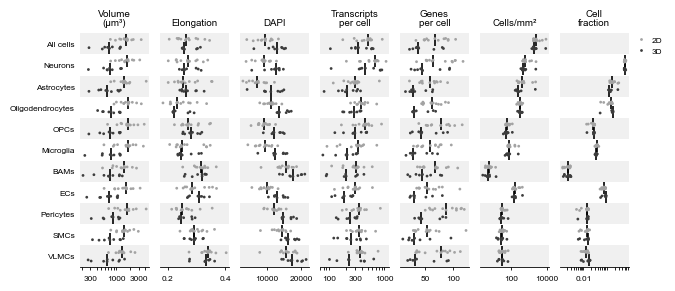

In [5]:
sums = gs[[*stats.values(), "n_cells"]].mul(gs.n_cells, axis=0).assign(n_cells=gs.n_cells).groupby([gs.group, gs.method]).sum(min_count=1)
df = sums[list(stats.values())].div(sums.n_cells, axis=0)
df["Cells/mm²"] = sums.n_cells / gs.groupby([gs.group, gs.method]).tissue_mm2.sum()
df["Cell fraction"] = (sums.n_cells / sums.n_cells["All cells"]).drop("All cells")
df = df.reset_index()
df.to_csv(out_dir / "celltype_general.csv", index=False)

order = ["All cells", "Neurons", "Astrocytes", "Oligodendrocytes", "OPCs", "Microglia", "BAMs", "ECs", "Pericytes", "SMCs", "VLMCs"]
assert set(order[1:]) == set(celltype_groups)
raw = {v: k for k, v in method_names.items()}
d = df[~df.method.str.startswith(("Raster", "Voronoi"))]
dim = d.method.map(raw).fillna("").str.startswith(tuple(methods_3D)).map({True: "3D", False: "2D"})
cols = d.columns[2:]
fig, axes = plt.subplots(1, len(cols), figsize=(180 / 25.4, len(order) * 7 / 25.4), sharey=True, gridspec_kw={"wspace": 0.15})
for ax, col in zip(axes, cols):
    kw = dict(data=d, x=col, y="group", order=order, hue=dim, hue_order=["2D", "3D"], ax=ax)
    sns.stripplot(**kw, dodge=True, jitter=0.12, palette=dim_colors, size=2, linewidth=0, legend=ax is axes[-1])
    sns.pointplot(**kw, dodge=0.4, palette={"2D": "black", "3D": "black"}, **median)
    style(ax, col, len(order))
sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1, 1), **legend)
for ext in ["svg", "png"]:
    fig.savefig(out_dir / f"celltype_general.{ext}", bbox_inches="tight", dpi=600, transparent=True)